Importing

In [8]:
import os, sys, math, random, json, re, time, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras import layers, models, Model, Sequential
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.layers import (Input, Embedding, Conv1D, GlobalMaxPooling1D, MaxPooling1D, Dense,
                                     Dropout, BatchNormalization, LSTM, GRU, Bidirectional, Flatten)
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score
print(tf.__version__)


2.4.1


Dataset

In [9]:
# import pandas as pd

# file1_url = 'phishing.csv'
# file2_url = 'not-phishing.csv'

# df1 = pd.read_csv(file1_url)
# df2 = pd.read_csv(file2_url)

# df2['brands'] = pd.NA

# combined_df = pd.concat([df1, df2], ignore_index=True)

# combined_df['label'] = combined_df['security_state'].map({'insecure': 0, 'secure': 1})
# combined_df = combined_df[['url', 'label']].dropna(subset=["url", "label"]).copy()
# combined_df["label"] = combined_df["label"].astype(int)

# combined_df.to_csv('combined_data.csv', index=False)

# df = pd.read_csv('combined_data.csv')

# if 'url' not in df.columns or 'security_state' not in df.columns:
#     print("Available columns:", df.columns.tolist())
#     if 'url' not in df.columns:
#         print("'url' column not found in the dataset.")
#     if 'security_state' not in df.columns:
#         print("'security_state' column not found in the dataset.")

# df['label'] = df['security_state'].map({'insecure': 0, 'secure': 1})
# df = df[['url', 'label']].dropna(subset=["url", "label"]).copy()
# df["label"] = df["label"].astype(int)

# print(df.head())
# print("Class balance:\n", df["label"].value_counts())


In [ ]:
import pandas as pd

#url = 'Shashwatwork.csv'
df = pd.read_csv('../dataset_phishing.csv')


expected_cols = {"url", "status"}

if 'url' not in df.columns or 'status' not in df.columns:
    print("Available columns:", df.columns.tolist())
    if 'url' not in df.columns:
        print("'url' column not found in the dataset.")
    if 'status' not in df.columns:
        print("'status' column not found in the dataset.")


df['label'] = df['status'].map({'legitimate': 0, 'phishing': 1})
df = df[['url', 'label']].dropna(subset=["url", "label"]).copy()
df["label"] = df["label"].astype(int)

print(df.head())

print("Class balance:\n", df["label"].value_counts())


                                                 url  label
0              http://www.crestonwood.com/router.php      0
1  http://shadetreetechnology.com/V4/validation/a...      1
2  https://support-appleld.com.secureupdate.duila...      1
3                                 http://rgipt.ac.in      0
4  http://www.iracing.com/tracks/gateway-motorspo...      0
Class balance:
 0    5715
1    5715
Name: label, dtype: int64


In [ ]:
# import pandas as pd
# import numpy as np
# import re

# # Load df2
# df2 = pd.read_csv('../datasets_100w.csv')
# print(df2.shape)
# df2.head()

# # Check if the necessary columns are available in df2
# expected_cols = {"url", "status"}
# if 'url' not in df2.columns or 'status' not in df2.columns:
#     print("Available columns:", df2.columns.tolist())
#     if 'url' not in df2.columns:
#         print("'url' column not found in the dataset.")
#     if 'status' not in df2.columns:
#         print("'status' column not found in the dataset.")

# # Mapping 'status' to 'label': 0 for legitimate, 1 for phishing
# df2['label'] = df2['status'].map({'legitimate': 0, 'phishing': 1})

# # Selecting the relevant columns and cleaning the dataset
# df2 = df2[['url', 'label']].dropna(subset=["url", "label"]).copy()
# df2["label"] = df2["label"].astype(int)

# # Print the head of df2 and the class distribution
# print(df2.head())
# print("Class balance:\n", df2["label"].value_counts())
# # Load df3_1
# df3_1 = pd.read_csv('../data.csv')
# print(df3_1.shape)
# df3_1.head()

# # Check if 'url' and 'label' columns are in df3_1
# expected_cols = {"url", "label"}
# if 'url' not in df3_1.columns or 'label' not in df3_1.columns:
#     print("Available columns:", df3_1.columns.tolist())
#     if 'url' not in df3_1.columns:
#         print("'url' column not found in the dataset.")
#     if 'label' not in df3_1.columns:
#         print("'label' column not found in the dataset.")

# # Mapping 'label' values: 0 for legitimate, 1 for phishing
# df3_1['label'] = df3_1['label'].map({'legitimate': 0, 'phishing': 1})

# # Load df3_2 (no headers)
# df3_2 = pd.read_csv('../data2.csv', header=None)
# print(df3_2.shape)
# df3_2.head()

# # Rename columns for df3_2
# df3_2.rename(columns={0: 'url', 1: 'label'}, inplace=True)

# # Mapping 'label' values for df3_2
# df3_2['label'] = df3_2['label'].map({'legitimate': 0, 'phishing': 1})

# # Concatenate df3_1 and df3_2
# df3 = pd.concat([df3_1, df3_2])
# df3.drop_duplicates(inplace=True)
# df3.dropna(inplace=True)
# df3.reset_index(drop=True, inplace=True)

# # Print the class distribution and the shape of df3
# print(df3['label'].value_counts())
# print(df3.shape)
# df4 = pd.read_csv('../phising_alexa.csv')
# print(df4.shape)
# df4.head()

# # Check class balance in df4
# df4['label'].value_counts()

# # Balancing the dataset: sample an equal number of legitimate (label=0) and phishing (label=1) URLs
# df4_0 = df4[df4['label'] == 0].sample(15746, random_state=28)
# df4_1 = df4[df4['label'] == 1]

# # Concatenate the two dataframes
# df4 = pd.concat([df4_0, df4_1])
# df4.drop_duplicates(inplace=True)
# df4.dropna(inplace=True)
# df4.reset_index(drop=True, inplace=True)

# # Check the class distribution and print the shape of df4
# print(df4['label'].value_counts())
# print(df4.shape)

# combined_df = pd.concat([df1, df2, df3, df4], ignore_index=True)

# # Final combined dataset preprocessing (if needed)
# combined_df['label'] = combined_df['label'].astype(int)
# combined_df = combined_df[['url', 'label']].dropna(subset=["url", "label"]).copy()

# # Print combined dataset details
# print(combined_df.head())
# print("Combined Class balance:\n", combined_df['label'].value_counts())



Preprocessing

In [74]:

#char encoding
USE_FIXED_ASCII = False
MAX_LEN = 123

def build_char_vocab(urls, use_fixed_ascii=False, min_freq=1):
    if use_fixed_ascii:
        chars = [chr(i) for i in range(32,127)]
        stoi = {c:i+2 for i,c in enumerate(chars)}
    else:
        from collections import Counter
        cnt = Counter()
        for u in urls:
            cnt.update(list(str(u)))
        chars = [c for c,f in cnt.items() if f>=min_freq]
        chars = sorted(chars)
        stoi = {c:i+2 for i,c in enumerate(chars)}
    itos = {i:c for c,i in stoi.items()}
    return stoi, itos

def encode_urls(urls, stoi, max_len=200):
    seqs = []
    for u in urls:
        arr = []
        for ch in str(u):
            arr.append(stoi.get(ch, 1))
        seqs.append(arr[:max_len])
    X = pad_sequences(seqs, maxlen=max_len, padding="post", truncating="post", value=0)
    return X

stoi, itos = build_char_vocab(df["url"].tolist(), use_fixed_ascii=USE_FIXED_ASCII)
vocab_size = max(stoi.values())+1
print("Vocab size:", vocab_size, "| MAX_LEN:", MAX_LEN)

X = encode_urls(df["url"].tolist(), stoi, max_len=MAX_LEN)
y = df["label"].values

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
X_val, X_test, y_val, y_test   = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

print("Train/Val/Test shapes:", X_train.shape, X_val.shape, X_test.shape)


Vocab size: 102 | MAX_LEN: 123
Train/Val/Test shapes: (8001, 123) (1714, 123) (1715, 123)


**Paper DL_1**

Model

In [75]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import RNN, LSTM, GRU, SimpleRNNCell

class IdentityRNNCell(SimpleRNNCell):
    def __init__(self, units, **kwargs):
        super(IdentityRNNCell, self).__init__(units, activation='relu', **kwargs)

    def build(self, input_shape):
        super(IdentityRNNCell, self).build(input_shape)
        self.kernel = self.add_weight(shape=(input_shape[-1], self.units),
                              initializer='glorot_uniform', name='kernel')

        self.recurrent_kernel = self.add_weight(
              shape=(self.units, self.units),
              initializer=tf.keras.initializers.Constant(np.eye(self.units)),
              name='recurrent_kernel'
          )
        self.bias = self.add_weight(shape=(self.units,),
                                    initializer='zeros', name='bias')

    def call(self, inputs, states, training=None):
        return super(IdentityRNNCell, self).call(inputs, states, training)


def build_model(vocab_size, max_len, embed_dim=256, recurrent_type='LSTM', hidden_units=256, dropout=0.1, filters=128, kernel_size=5,learning_rate=0.001):
    inp = Input(shape=(max_len,))
    x = Embedding(vocab_size, embed_dim, input_length=max_len, name='embedding')(inp)
    if recurrent_type == 'RNN':
        x = RNN(SimpleRNNCell(hidden_units), return_sequences=True)(x)
    elif recurrent_type == 'LSTM':
        x = LSTM(hidden_units, return_sequences=True)(x)
    elif recurrent_type == 'GRU':
        x = GRU(hidden_units, return_sequences=True)(x)
    elif recurrent_type == 'I-RNN':
        x = RNN(IdentityRNNCell(hidden_units), return_sequences=True)(x)

    x = Conv1D(filters, kernel_size, activation='relu')(x)
    x = MaxPooling1D(2)(x)
    x = Flatten()(x)
    x = Dense(256, activation='relu')(x)
    x = Dropout(dropout)(x)
    out = Dense(1, activation='sigmoid')(x)


    model = Model(inp, out)

    model.compile(optimizer=Adam(learning_rate=learning_rate), loss='binary_crossentropy', metrics=['accuracy'])

    return model



Model Eval

Training with learning rate: 0.01
Evaluating RNN model...
Epoch 1/1000
126/126 [==============================] - 19s 143ms/step - loss: 47.7128 - accuracy: 0.4972 - val_loss: 0.6932 - val_accuracy: 0.5000
Epoch 2/1000
126/126 [==============================] - 18s 140ms/step - loss: 0.6933 - accuracy: 0.4987 - val_loss: 0.6932 - val_accuracy: 0.5000
Epoch 3/1000
126/126 [==============================] - 18s 142ms/step - loss: 0.6932 - accuracy: 0.5007 - val_loss: 0.6932 - val_accuracy: 0.5000
Epoch 4/1000
126/126 [==============================] - 18s 140ms/step - loss: 0.6933 - accuracy: 0.5037 - val_loss: 0.6931 - val_accuracy: 0.5000
Epoch 5/1000
126/126 [==============================] - 18s 139ms/step - loss: 0.6932 - accuracy: 0.5017 - val_loss: 0.6932 - val_accuracy: 0.5000
Epoch 6/1000
126/126 [==============================] - 18s 140ms/step - loss: 0.6934 - accuracy: 0.4906 - val_loss: 0.6932 - val_accuracy: 0.5000
Epoch 7/1000
126/126 [==============================] - 18s

Epoch 17/1000
126/126 [==============================] - 33s 262ms/step - loss: 0.6936 - accuracy: 0.5012 - val_loss: 0.6931 - val_accuracy: 0.5000
Epoch 18/1000
126/126 [==============================] - 33s 263ms/step - loss: 0.6931 - accuracy: 0.5048 - val_loss: 0.6934 - val_accuracy: 0.5000
Epoch 19/1000
126/126 [==============================] - 33s 263ms/step - loss: 0.6936 - accuracy: 0.4943 - val_loss: 0.6932 - val_accuracy: 0.5000
Validation accuracy for GRU with learning rate 0.01: 0.5
Training with learning rate: 0.05
Evaluating RNN model...
Epoch 1/1000
126/126 [==============================] - 19s 145ms/step - loss: 912.8522 - accuracy: 0.4832 - val_loss: 0.6915 - val_accuracy: 0.5117
Epoch 2/1000
126/126 [==============================] - 18s 141ms/step - loss: 0.6947 - accuracy: 0.5031 - val_loss: 0.6914 - val_accuracy: 0.5000
Epoch 3/1000
126/126 [==============================] - 18s 140ms/step - loss: 0.6917 - accuracy: 0.5036 - val_loss: 0.6886 - val_accuracy: 0.500

126/126 [==============================] - 19s 143ms/step - loss: 3937.7171 - accuracy: 0.5325 - val_loss: 0.6877 - val_accuracy: 0.5000
Epoch 2/1000
126/126 [==============================] - 18s 140ms/step - loss: 13.0179 - accuracy: 0.5238 - val_loss: 0.6940 - val_accuracy: 0.5035
Epoch 3/1000
126/126 [==============================] - 18s 140ms/step - loss: 0.6923 - accuracy: 0.5070 - val_loss: 0.6911 - val_accuracy: 0.5035
Epoch 4/1000
126/126 [==============================] - 18s 140ms/step - loss: 0.6965 - accuracy: 0.4977 - val_loss: 0.6909 - val_accuracy: 0.5035
Epoch 5/1000
126/126 [==============================] - 18s 140ms/step - loss: 0.6964 - accuracy: 0.4951 - val_loss: 0.6922 - val_accuracy: 0.5035
Epoch 6/1000
126/126 [==============================] - 18s 141ms/step - loss: 0.6946 - accuracy: 0.5012 - val_loss: 0.6923 - val_accuracy: 0.5000
Epoch 7/1000
126/126 [==============================] - 18s 140ms/step - loss: 0.6951 - accuracy: 0.5017 - val_loss: 0.6913 - v

126/126 [==============================] - 44s 338ms/step - loss: 157824.6665 - accuracy: 0.5396 - val_loss: 5.8455 - val_accuracy: 0.5041
Epoch 2/1000
126/126 [==============================] - 42s 333ms/step - loss: 0.9379 - accuracy: 0.5097 - val_loss: 2.2875 - val_accuracy: 0.5041
Epoch 3/1000
126/126 [==============================] - 42s 337ms/step - loss: 0.7410 - accuracy: 0.5005 - val_loss: 2.6018 - val_accuracy: 0.4988
Epoch 4/1000
126/126 [==============================] - 43s 339ms/step - loss: 0.7047 - accuracy: 0.5062 - val_loss: 2.6199 - val_accuracy: 0.5006
Epoch 5/1000
126/126 [==============================] - 43s 339ms/step - loss: 0.7131 - accuracy: 0.5037 - val_loss: 2.5960 - val_accuracy: 0.4988
Epoch 6/1000
126/126 [==============================] - 43s 338ms/step - loss: 0.7079 - accuracy: 0.4838 - val_loss: 2.6352 - val_accuracy: 0.5006
Epoch 7/1000
126/126 [==============================] - 43s 339ms/step - loss: 0.7157 - accuracy: 0.4999 - val_loss: 2.5934 - 

/home/mainaksen/.conda/envs/may23/lib/python3.7/site-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 130 (\x82) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
/home/mainaksen/.conda/envs/may23/lib/python3.7/site-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 131 (\x83) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
/home/mainaksen/.conda/envs/may23/lib/python3.7/site-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 145 (\x91) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
/home/mainaksen/.conda/envs/may23/lib/python3.7/site-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 20613 (\N{CJK UNIFIED IDEOGRAPH-5085}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
/home/mainaksen/.conda/envs/may23/lib/python3.7/site-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 25312 (\N{CJK UNIFIED IDEOGRAPH-62E0}) missing from current font.
  fig.canvas.print_fi

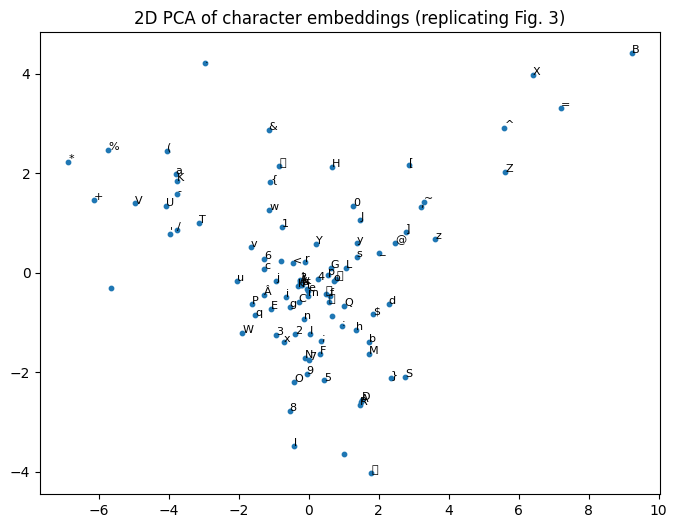

In [76]:
from sklearn.metrics import classification_report, roc_auc_score
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.callbacks import ReduceLROnPlateau

MAX_LEN = 123
def evaluate_recurrent_models(X_train, y_train, X_val, y_val, vocab_size, max_len):
    recurrent_types = ['RNN', 'LSTM', 'GRU']
    learning_rates = [0.01, 0.05, 0.1, 0.2, 0.5]  # Manual learning rates
    best_accuracy = 0
    best_model = None
    best_recurrent_type = ''
    early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

    for lr in learning_rates:
        print(f"Training with learning rate: {lr}")
        for recurrent_type in recurrent_types:
            print(f"Evaluating {recurrent_type} model...")
            model = build_model(vocab_size, max_len, recurrent_type=recurrent_type, learning_rate=lr)

            model.fit(X_train, y_train, epochs=1000, batch_size=64, validation_data=(X_val, y_val), verbose=1, callbacks=[early_stopping])

            val_loss, val_accuracy = model.evaluate(X_val, y_val, verbose=0)
            print(f"Validation accuracy for {recurrent_type} with learning rate {lr}: {val_accuracy}")

            if val_accuracy > best_accuracy:
                best_accuracy = val_accuracy
                best_model = model
                best_recurrent_type = recurrent_type

    print(f"Best model: {best_recurrent_type} with validation accuracy: {best_accuracy}")
    return best_model
best_model = evaluate_recurrent_models(X_train, y_train, X_val, y_val, vocab_size, MAX_LEN)

#best model eval
test_loss, test_accuracy = best_model.evaluate(X_test, y_test, verbose=0)
print(f"Test accuracy of the best model: {test_accuracy}")
y_pred = (best_model.predict(X_test) > 0.5).astype("int32")
print(classification_report(y_test, y_pred))
print("ROC AUC Score:", roc_auc_score(y_test, y_pred))


from sklearn.decomposition import PCA
emb_weights = best_model.get_layer('embedding').get_weights()[0]
pca = PCA(n_components=2)
emb_2d = pca.fit_transform(emb_weights)
plt.figure(figsize=(8,6))
plt.scatter(emb_2d[:,0], emb_2d[:,1], s=10)
for i, c in enumerate(list(itos.values())[:100]):  # label first 100 chars
    plt.text(emb_2d[i,0], emb_2d[i,1], c, fontsize=8)
plt.title("2D PCA of character embeddings (replicating Fig. 3)")
plt.show()


**Paper DL_2**

In [10]:
# Preprocessing for character encoding
USE_FIXED_ASCII = False
MAX_LEN = 200  # Max length of the URL (200 as per the paper)
EMBED_DIM = 32  # Dimension of the character embeddings

def build_char_vocab(urls, use_fixed_ascii=False, min_freq=1):
    if use_fixed_ascii:
        chars = [chr(i) for i in range(32, 127)]
        stoi = {c: i + 2 for i, c in enumerate(chars)}
    else:
        from collections import Counter
        cnt = Counter()
        for u in urls:
            cnt.update(list(str(u)))
        chars = [c for c, f in cnt.items() if f >= min_freq]
        chars = sorted(chars)
        stoi = {c: i + 2 for i, c in enumerate(chars)}  # 0 for padding, 1 for unknown characters
    itos = {i: c for c, i in stoi.items()}
    return stoi, itos

def encode_urls(urls, stoi, max_len=200):
    seqs = []
    for u in urls:
        arr = []
        for ch in str(u):
            arr.append(stoi.get(ch, 1))  # Use 1 for unknown characters
        seqs.append(arr[:max_len])
    X = pad_sequences(seqs, maxlen=max_len, padding="pre", truncating="pre", value=0)  # Padding at the beginning
    return X

# Build vocabulary
stoi, itos = build_char_vocab(df["url"].tolist(), use_fixed_ascii=USE_FIXED_ASCII)
vocab_size = max(stoi.values()) + 1
print("Vocab size:", vocab_size, "| MAX_LEN:", MAX_LEN)

# Encode the URLs
X = encode_urls(df["url"].tolist(), stoi, max_len=MAX_LEN)
y = df["label"].values

# Split the data into train, validation, and test sets
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

print("Train/Val/Test shapes:", X_train.shape, X_val.shape, X_test.shape)


Vocab size: 102 | MAX_LEN: 200
Train/Val/Test shapes: (8001, 200) (1714, 200) (1715, 200)


In [11]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.optimizers import Adam
from tensorflow.keras import backend as K

def sum_pooling(x):
    return K.sum(x, axis=1)


def build_model(vocab_size, max_len=200, embed_dim=32, filters=256, kernel_sizes=[2, 3, 4, 5], dense_units=1024, dropout_rate=0.5):
    inp = layers.Input(shape=(max_len,))

    #character embedding
    x = layers.Embedding(input_dim=vocab_size, output_dim=embed_dim, input_length=max_len)(inp)
    conv_outputs = []
    for kernel_size in kernel_sizes:
        conv = layers.Conv1D(filters, kernel_size, activation='relu')(x)
        conv = layers.Lambda(sum_pooling)(conv)                           #custom, use globalaveragepooling if this does not work
        conv = layers.Flatten()(conv)
        conv_outputs.append(conv)
    x = layers.concatenate(conv_outputs, axis=-1)
    x = layers.LayerNormalization()(x)
    x = layers.Dropout(dropout_rate)(x)
    x = layers.Dense(dense_units, activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(dropout_rate)(x)
    x = layers.Dense(dense_units, activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(dropout_rate)(x)
    x = layers.Dense(dense_units, activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(dropout_rate)(x)

    #output layer
    out = layers.Dense(1, activation='sigmoid')(x)

    model = models.Model(inputs=inp, outputs=out)

    model.compile(optimizer=Adam(learning_rate=0.001), loss='binary_crossentropy', metrics=['accuracy'])

    return model

model = build_model(vocab_size, max_len=MAX_LEN)

model.summary()


Model: "model_4"
__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
input_5 (InputLayer)            [(None, 200)]        0                                            
__________________________________________________________________________________________________
embedding (Embedding)           (None, 200, 32)      3264        input_5[0][0]                    
__________________________________________________________________________________________________
conv1d_4 (Conv1D)               (None, 199, 256)     16640       embedding[0][0]                  
__________________________________________________________________________________________________
conv1d_5 (Conv1D)               (None, 198, 256)     24832       embedding[0][0]                  
____________________________________________________________________________________________

In [12]:
from sklearn.metrics import roc_auc_score

model.fit(X_train, y_train, epochs=100, batch_size=256, validation_data=(X_val, y_val))

test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"Test accuracy of the best model: {test_accuracy}")
y_pred = (model.predict(X_test) > 0.5).astype("int32")
print("ROC AUC Score:", roc_auc_score(y_test, y_pred))

print(classification_report(y_test, y_pred))


Epoch 1/100
32/32 [==============================] - 7s 178ms/step - loss: 1.0270 - accuracy: 0.5403 - val_loss: 0.6376 - val_accuracy: 0.6377
Epoch 2/100
32/32 [==============================] - 5s 170ms/step - loss: 0.7516 - accuracy: 0.5928 - val_loss: 0.5202 - val_accuracy: 0.7258
Epoch 3/100
32/32 [==============================] - 5s 167ms/step - loss: 0.6024 - accuracy: 0.6780 - val_loss: 0.4344 - val_accuracy: 0.8215
Epoch 4/100
32/32 [==============================] - 6s 172ms/step - loss: 0.4872 - accuracy: 0.7735 - val_loss: 0.4110 - val_accuracy: 0.8291
Epoch 5/100
32/32 [==============================] - 5s 169ms/step - loss: 0.4478 - accuracy: 0.7965 - val_loss: 0.4337 - val_accuracy: 0.8133
Epoch 6/100
32/32 [==============================] - 6s 173ms/step - loss: 0.4321 - accuracy: 0.7979 - val_loss: 0.3761 - val_accuracy: 0.8302
Epoch 7/100
32/32 [==============================] - 6s 173ms/step - loss: 0.4127 - accuracy: 0.8108 - val_loss: 0.3750 - val_accuracy: 0.8326

Epoch 58/100
32/32 [==============================] - 5s 172ms/step - loss: 0.0572 - accuracy: 0.9764 - val_loss: 0.2813 - val_accuracy: 0.9236
Epoch 59/100
32/32 [==============================] - 6s 173ms/step - loss: 0.0544 - accuracy: 0.9795 - val_loss: 0.2984 - val_accuracy: 0.9224
Epoch 60/100
32/32 [==============================] - 6s 172ms/step - loss: 0.0613 - accuracy: 0.9768 - val_loss: 0.2528 - val_accuracy: 0.9265
Epoch 61/100
32/32 [==============================] - 5s 172ms/step - loss: 0.0527 - accuracy: 0.9779 - val_loss: 0.3099 - val_accuracy: 0.9212
Epoch 62/100
32/32 [==============================] - 6s 174ms/step - loss: 0.0462 - accuracy: 0.9794 - val_loss: 0.2948 - val_accuracy: 0.9247
Epoch 63/100
32/32 [==============================] - 5s 172ms/step - loss: 0.0490 - accuracy: 0.9791 - val_loss: 0.3433 - val_accuracy: 0.9142
Epoch 64/100
32/32 [==============================] - 6s 172ms/step - loss: 0.0518 - accuracy: 0.9788 - val_loss: 0.2685 - val_accuracy:

In [14]:
!pip install gensim

Defaulting to user installation because normal site-packages is not writeable
ERROR: Could not find a version that satisfies the requirement gensim (from versions: none)
ERROR: No matching distribution found for gensim


**Paper_DL(22)_3**

In [13]:

from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Embedding, Bidirectional, LSTM, GlobalMaxPooling1D, Dense, Dropout, Concatenate
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.initializers import Constant
import gensim
from gensim.models import Word2Vec



Defaulting to user installation because normal site-packages is not writeable
ERROR: Could not find a version that satisfies the requirement gensim (from versions: none)
ERROR: No matching distribution found for gensim


ModuleNotFoundError: No module named 'gensim'

In [ ]:
X = df['url']
Y = df['label'].values
original_urls = df["url"].tolist()
original_url_lengths = [len(url) for url in original_urls]

In [ ]:
original_url_lengths = [len(url) for url in original_urls]
max_url = max(original_urls, key=len)
min_url = min(original_urls, key=len)
average_length = sum(original_url_lengths) / len(original_urls)


In [ ]:
cleaned_urls = [re.sub(r'^https?:\/\/', '', url) for url in original_urls]
allowed_characters = sorted(set(''.join(cleaned_urls)))
char_dict = {char: idx + 1 for idx, char in enumerate(allowed_characters)}
char_dict['<PAD>'] = 0
char_dict['<UNK>'] = len(char_dict)
max_url_length = 255


In [ ]:
def url_to_char_vector(url):
    url = re.sub(r'^https?:\/\/', '', url)
    vector = [char_dict.get(char, char_dict['<UNK>']) for char in url[:max_url_length]]
    if len(vector) < max_url_length:
        vector += [char_dict['<PAD>']] * (max_url_length - len(vector))
    return vector

char_vectors = np.array([url_to_char_vector(url) for url in cleaned_urls])


Model

In [ ]:
def build_pdrcnn_model(vocab_size, max_len=255, embed_dim=64, filters=32, kernel_sizes=[5, 6, 7], dense_units=1024, dropout_rate=0.9):
    input_char = layers.Input(shape=(max_len,))  # Only use input_char here
    x_char = layers.Embedding(input_dim=vocab_size, output_dim=embed_dim, input_length=max_len)(input_char)
    x_char = layers.Bidirectional(layers.LSTM(64, return_sequences=True))(x_char)

    conv_outputs_char = []
    for kernel_size in kernel_sizes:
        conv = layers.Conv1D(filters, kernel_size, activation='relu')(x_char)
        conv = layers.MaxPooling1D(pool_size=2)(conv)
        conv = layers.Dropout(dropout_rate)(conv)
        conv = layers.Flatten()(conv)
        conv_outputs_char.append(conv)

    x = layers.concatenate(conv_outputs_char, axis=-1)
    x = layers.Dense(dense_units, activation='relu')(x)
    x = layers.Dropout(dropout_rate)(x)

    out = layers.Dense(1, activation='sigmoid')(x)

    model = models.Model(inputs=input_char, outputs=out)
    model.compile(optimizer=Adam(learning_rate=0.001), loss='binary_crossentropy', metrics=['accuracy'])

    return model

model = build_pdrcnn_model(vocab_size = len(char_dict), max_len=255, embed_dim=64)
model.summary()
X_train_char, X_test_char, y_train, y_test = train_test_split(char_vectors, Y, test_size=0.2, random_state=42)
model.fit(X_train_char, y_train, epochs=32, batch_size=2048, validation_data=(X_test_char, y_test))

Model Eval

In [ ]:
from sklearn.metrics import classification_report, roc_auc_score
test_loss, test_accuracy = model.evaluate(X_test_char, y_test)
print(f"Test accuracy: {test_accuracy}")
y_pred = (model.predict(X_test_char) > 0.5).astype("int32")

print("Classification Report:")
print(classification_report(y_test, y_pred))
roc_auc = roc_auc_score(y_test, y_pred)
print("ROC AUC Score:", roc_auc)


**23a(DL)**

In [16]:
USE_FIXED_ASCII = True
MAX_LEN = 128  # Update to match the paper's maximum length

#fixed chars as per paper
def build_char_vocab(urls, use_fixed_ascii=False):
    if use_fixed_ascii:
        chars = ['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z',
                 '0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '_']
        stoi = {c: i+2 for i, c in enumerate(chars)}  # index starts from 2
    else:
        from collections import Counter
        cnt = Counter()
        for u in urls:
            cnt.update(list(str(u)))
        chars = [c for c, f in cnt.items() if f >= 1]
        chars = sorted(chars)
        stoi = {c: i+2 for i, c in enumerate(chars)}
    itos = {i: c for c, i in stoi.items()}
    return stoi, itos

def encode_urls(urls, stoi, max_len=256):
    seqs = []
    for u in urls:
        arr = []
        for ch in str(u):
            arr.append(stoi.get(ch, 1))  # unknown characters mapped to 1
        seqs.append(arr[:max_len])
    X = pad_sequences(seqs, maxlen=max_len, padding="post", truncating="post", value=0)
    return X

stoi, itos = build_char_vocab(df["url"].tolist(), use_fixed_ascii=USE_FIXED_ASCII)
vocab_size = max(stoi.values()) + 1
print("Vocab size:", vocab_size, "| MAX_LEN:", MAX_LEN)

X = encode_urls(df["url"].tolist(), stoi, max_len=MAX_LEN)
y = df["label"].values

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

print("Train/Val/Test shapes:", X_train.shape, X_val.shape, X_test.shape)

Vocab size: 39 | MAX_LEN: 128
Train/Val/Test shapes: (8001, 128) (1714, 128) (1715, 128)


Model

In [21]:
from tensorflow.keras.optimizers import SGD
from tensorflow.keras.callbacks import LearningRateScheduler

def lr_schedule(epoch, lr):
    if epoch==0:
        return 0.1
    elif epoch==1:
        return 0.01
    elif epoch<6:
        return 0.001
    else:
         return 0.0005
        

def build_cnn_model(input_shape, vocab_size, max_len=128, embedding_dim=16):
    model = Sequential()

    model.add(Embedding(input_dim=vocab_size, output_dim=embedding_dim, input_length=max_len))

    model.add(Conv1D(filters=64, kernel_size=8, activation='relu', padding='same'))
    model.add(MaxPooling1D(pool_size=2))

    model.add(Conv1D(filters=16, kernel_size=16, activation='relu', padding='same'))
    model.add(MaxPooling1D(pool_size=2))

    model.add(Conv1D(filters=32, kernel_size=32, activation='relu', padding='same'))
    model.add(MaxPooling1D(pool_size=2))

    model.add(Flatten())
    model.add(Dense(32, activation='relu'))
    model.add(Dropout(0.5))
    sgd_optimizer=SGD(lr=0.1, momentum=0.5)
    
    #output layer
    model.add(Dense(1, activation='sigmoid'))
    model.compile(optimizer=sgd_optimizer, loss='binary_crossentropy', metrics=['accuracy'])


    return model

model = build_cnn_model(input_shape=X_train.shape[1:], vocab_size=vocab_size)
model.summary()


Model: "sequential_1"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
embedding_2 (Embedding)      (None, 128, 16)           624       
_________________________________________________________________
conv1d_11 (Conv1D)           (None, 128, 64)           8256      
_________________________________________________________________
max_pooling1d_7 (MaxPooling1 (None, 64, 64)            0         
_________________________________________________________________
conv1d_12 (Conv1D)           (None, 64, 16)            16400     
_________________________________________________________________
max_pooling1d_8 (MaxPooling1 (None, 32, 16)            0         
_________________________________________________________________
conv1d_13 (Conv1D)           (None, 32, 32)            16416     
_________________________________________________________________
max_pooling1d_9 (MaxPooling1 (None, 16, 32)           

Model Eval

In [22]:
from sklearn.metrics import classification_report, roc_auc_score
lr_scheduler = LearningRateScheduler(lr_schedule)
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=15,
    batch_size=45,
    callbacks=[lr_scheduler],
    verbose=1
)

#ravel shape adjustment used
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"Test accuracy: {test_accuracy:.4f}")

y_proba = model.predict(X_test).ravel()
y_pred = (y_proba > 0.5).astype(int)

print("Classification Report:")
print(classification_report(y_test, y_pred))
print("ROC AUC Score:", roc_auc_score(y_test, y_proba))


Epoch 1/15
178/178 [==============================] - 3s 14ms/step - loss: 0.6911 - accuracy: 0.5103 - val_loss: 0.6531 - val_accuracy: 0.5968
Epoch 2/15
178/178 [==============================] - 2s 13ms/step - loss: 0.6482 - accuracy: 0.5982 - val_loss: 0.6373 - val_accuracy: 0.6424
Epoch 3/15
178/178 [==============================] - 2s 13ms/step - loss: 0.6470 - accuracy: 0.6018 - val_loss: 0.6365 - val_accuracy: 0.6231
Epoch 4/15
178/178 [==============================] - 2s 13ms/step - loss: 0.6377 - accuracy: 0.6144 - val_loss: 0.6355 - val_accuracy: 0.6231
Epoch 5/15
178/178 [==============================] - 2s 13ms/step - loss: 0.6394 - accuracy: 0.5990 - val_loss: 0.6348 - val_accuracy: 0.6272
Epoch 6/15
178/178 [==============================] - 2s 13ms/step - loss: 0.6410 - accuracy: 0.6055 - val_loss: 0.6344 - val_accuracy: 0.6138
Epoch 7/15
178/178 [==============================] - 2s 13ms/step - loss: 0.6426 - accuracy: 0.6051 - val_loss: 0.6342 - val_accuracy: 0.6155

**38_(DL)**

In [23]:
from urllib.parse import urlparse
from sklearn.preprocessing import StandardScaler

def extract_features(url):
    parsed = urlparse(url)
    features = {}
    special_chars = ['.', '-', '_', '/', '?', '=', '@', '&', '!', '~', ',', '+', '*', '#', '$', '%']
    for ch in special_chars:
        features[f'count_{ch}'] = url.count(ch)
    features['url_length'] = len(url)
    features['tld_length'] = len(parsed.netloc.split('.')[-1]) if '.' in parsed.netloc else 0
    features['has_email'] = 1 if re.search(r'\S+@\S+', url) else 0
    features['has_https'] = 1 if url.lower().startswith("https") else 0
    return features

feature_df = pd.DataFrame([extract_features(u) for u in df['url']])
y = df["label"].values

scaler = StandardScaler()
X = scaler.fit_transform(feature_df)

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

print("Train/Val/Test shapes:", X_train.shape, X_val.shape, X_test.shape)


Train/Val/Test shapes: (8572, 20) (1429, 20) (1429, 20)


In [31]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

def build_lstm_model(input_dim):
    model = Sequential()
    model.add(LSTM(128, activation='tanh', recurrent_initializer='orthogonal', input_shape=(input_dim,1)))
    model.add(Dropout(0.5))
    model.add(Dense(32, activation='sigmoid'))
    model.add(Dense(1, activation='sigmoid'))
    model.compile(optimizer=Adam(learning_rate=1e-3), loss='binary_crossentropy', metrics=['accuracy'])
    return model

def build_gru_model(input_dim):
    model = Sequential()
    model.add(GRU(128, activation='sigmoid', recurrent_initializer='orthogonal', input_shape=(input_dim,1)))
    model.add(Dense(32, activation='sigmoid'))
    model.add(Dropout(0.5))
    model.add(Dense(1, activation='sigmoid'))
    model.compile(optimizer=Adam(learning_rate=1e-3), loss='binary_crossentropy', metrics=['accuracy'])
    return model

X_train_rnn = np.expand_dims(X_train, -1)
X_val_rnn = np.expand_dims(X_val, -1)
X_test_rnn = np.expand_dims(X_test, -1)

callbacks = [
    EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.1, patience=5, min_lr=1e-5)
]

lstm_model = build_lstm_model(X_train.shape[1])
history_lstm = lstm_model.fit(X_train_rnn, y_train, validation_data=(X_val_rnn, y_val),
                              epochs=40, batch_size=500, callbacks=callbacks, verbose=1)

gru_model = build_gru_model(X_train.shape[1])
history_gru = gru_model.fit(X_train_rnn, y_train, validation_data=(X_val_rnn, y_val),
                            epochs=40, batch_size=500, callbacks=callbacks, verbose=1)


Epoch 1/40
18/18 [==============================] - 3s 120ms/step - loss: 0.6931 - accuracy: 0.5205 - val_loss: 0.6498 - val_accuracy: 0.5962
Epoch 2/40
18/18 [==============================] - 2s 94ms/step - loss: 0.6519 - accuracy: 0.5842 - val_loss: 0.6358 - val_accuracy: 0.6032
Epoch 3/40
18/18 [==============================] - 2s 95ms/step - loss: 0.6425 - accuracy: 0.5928 - val_loss: 0.6288 - val_accuracy: 0.6256
Epoch 4/40
18/18 [==============================] - 2s 95ms/step - loss: 0.6259 - accuracy: 0.6183 - val_loss: 0.6257 - val_accuracy: 0.6578
Epoch 5/40
18/18 [==============================] - 2s 96ms/step - loss: 0.6236 - accuracy: 0.6346 - val_loss: 0.6220 - val_accuracy: 0.6669
Epoch 6/40
18/18 [==============================] - 2s 95ms/step - loss: 0.6228 - accuracy: 0.6589 - val_loss: 0.6198 - val_accuracy: 0.6438
Epoch 7/40
18/18 [==============================] - 2s 94ms/step - loss: 0.6223 - accuracy: 0.6465 - val_loss: 0.6184 - val_accuracy: 0.6788
Epoch 8/40
1

Epoch 19/40
18/18 [==============================] - 2s 86ms/step - loss: 0.6437 - accuracy: 0.6049 - val_loss: 0.6210 - val_accuracy: 0.6347
Epoch 20/40
18/18 [==============================] - 1s 82ms/step - loss: 0.6362 - accuracy: 0.6231 - val_loss: 0.6182 - val_accuracy: 0.6431
Epoch 21/40
18/18 [==============================] - 1s 81ms/step - loss: 0.6315 - accuracy: 0.6267 - val_loss: 0.6118 - val_accuracy: 0.6473
Epoch 22/40
18/18 [==============================] - 1s 83ms/step - loss: 0.6209 - accuracy: 0.6423 - val_loss: 0.6060 - val_accuracy: 0.6550
Epoch 23/40
18/18 [==============================] - 2s 84ms/step - loss: 0.6249 - accuracy: 0.6372 - val_loss: 0.6034 - val_accuracy: 0.6690
Epoch 24/40
18/18 [==============================] - 1s 79ms/step - loss: 0.6187 - accuracy: 0.6403 - val_loss: 0.6019 - val_accuracy: 0.6627
Epoch 25/40
18/18 [==============================] - 1s 82ms/step - loss: 0.6175 - accuracy: 0.6499 - val_loss: 0.5998 - val_accuracy: 0.6627
Epoch 

Model Eval

In [32]:
lstm_eval = lstm_model.evaluate(X_test_rnn, y_test, verbose=0)
print("LSTM Test Loss, Accuracy:", lstm_eval)

gru_eval = gru_model.evaluate(X_test_rnn, y_test, verbose=0)
print("GRU Test Loss, Accuracy:", gru_eval)

y_pred_lstm = (lstm_model.predict(X_test_rnn) > 0.5).astype(int)
y_pred_gru = (gru_model.predict(X_test_rnn) > 0.5).astype(int)

print("\nLSTM Classification Report:\n", classification_report(y_test, y_pred_lstm))
print("\nGRU Classification Report:\n", classification_report(y_test, y_pred_gru))


LSTM Test Loss, Accuracy: [0.4910806715488434, 0.7550734877586365]
GRU Test Loss, Accuracy: [0.5786589980125427, 0.682995080947876]

LSTM Classification Report:
               precision    recall  f1-score   support

           0       0.73      0.81      0.77       715
           1       0.79      0.70      0.74       714

    accuracy                           0.76      1429
   macro avg       0.76      0.76      0.75      1429
weighted avg       0.76      0.76      0.75      1429


GRU Classification Report:
               precision    recall  f1-score   support

           0       0.64      0.83      0.72       715
           1       0.76      0.54      0.63       714

    accuracy                           0.68      1429
   macro avg       0.70      0.68      0.68      1429
weighted avg       0.70      0.68      0.68      1429



**28(1)**

Preprocessing

In [53]:
def preprocess_urls(urls, max_length=100, dict_size=64):
    char_dict = {chr(i): i-32 for i in range(32, 127)}
    char_dict[' '] = 0
    char_dict={k:v if v< dict_size else dict_size-1 for k,v in char_dict.items()}
    encoded_urls = []
    for url in urls:
        encoded_url = [char_dict.get(ch, 0) for ch in url]
        if len(encoded_url) < max_length:
            encoded_url += [0] * (max_length - len(encoded_url))
        else:
            encoded_url = encoded_url[:max_length]
        encoded_urls.append(encoded_url)
    X_int = np.array(encoded_urls)
    X_onehot = tf.keras.utils.to_categorical(X_int, num_classes=dict_size)
    return X_onehot

X = preprocess_urls(df["url"].values, max_length=100, dict_size=64)
y = df["label"].values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


Auto-encoder

In [55]:
from tensorflow.keras.layers import Reshape, Conv2D, MaxPooling2D, UpSampling2D, Flatten, Dense, Dropout, BatchNormalization, Conv2DTranspose
from tensorflow.keras.models import Sequential
def build_autoencoder(input_shape):
    model = Sequential()
    model.add(Reshape((input_shape[0], input_shape[1], 1), input_shape=input_shape))
    model.add(Conv2D(256, (2, 2), activation='tanh', padding='same'))
    model.add(MaxPooling2D((2, 2), padding='same'))
    model.add(Conv2D(512, (2, 2), activation='tanh', padding='same'))
    model.add(MaxPooling2D((2, 2), padding='same'))
    model.add(BatchNormalization())
    model.add(Conv2D(1024, (1, 1), activation='tanh', padding='same'))
    model.add(UpSampling2D((2, 2)))
    model.add(Conv2DTranspose(512, (2, 2), activation='tanh', padding='same'))
    model.add(UpSampling2D((2, 2)))
    model.add(Conv2D(512, (2, 2), activation='tanh', padding='same'))
    model.add(BatchNormalization())    
    model.add(Conv2D(1, (2, 2), activation='sigmoid', padding='same'))
    model.add(Flatten())
    model.add(Dense(input_shape[0] * input_shape[1]))
    model.add(Reshape((input_shape[0], input_shape[1])))
    model.compile(optimizer='adam', loss='mse')
    return model

autoencoder = build_autoencoder((100, 64))
autoencoder.summary()
history = autoencoder.fit(X_train, X_train, epochs=10, batch_size=32, validation_data=(X_test, X_test))

Model: "sequential_14"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
reshape_3 (Reshape)          (None, 100, 64, 1)        0         
_________________________________________________________________
conv2d_6 (Conv2D)            (None, 100, 64, 256)      1280      
_________________________________________________________________
max_pooling2d_2 (MaxPooling2 (None, 50, 32, 256)       0         
_________________________________________________________________
conv2d_7 (Conv2D)            (None, 50, 32, 512)       524800    
_________________________________________________________________
max_pooling2d_3 (MaxPooling2 (None, 25, 16, 512)       0         
_________________________________________________________________
batch_normalization_3 (Batch (None, 25, 16, 512)       2048      
_________________________________________________________________
conv2d_8 (Conv2D)            (None, 25, 16, 1024)    

Model

In [56]:
reconstructed_urls = autoencoder.predict(X_test)
mse = np.mean(np.square(X_test - reconstructed_urls), axis=(1,2))
threshold = np.percentile(mse, 95)
predictions = (mse > threshold).astype(int)


Model Eval

              precision    recall  f1-score   support

           0       0.53      0.99      0.69      1157
           1       0.90      0.09      0.17      1129

    accuracy                           0.55      2286
   macro avg       0.71      0.54      0.43      2286
weighted avg       0.71      0.55      0.43      2286

[[1145   12]
 [1026  103]]


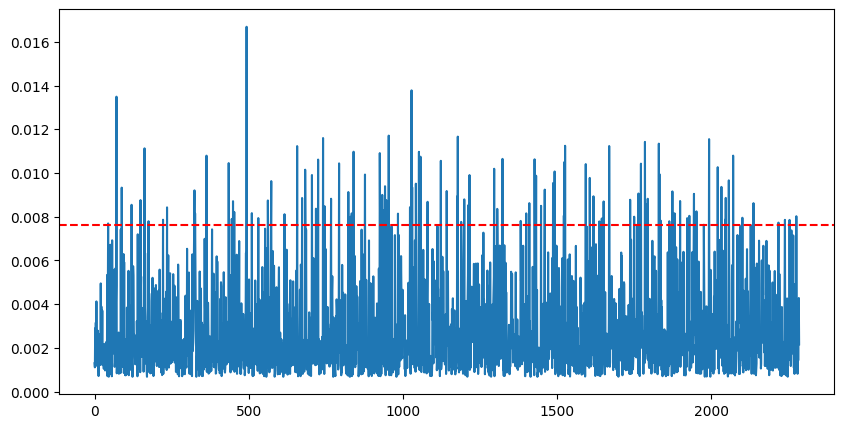

In [57]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

print(classification_report(y_test, predictions))
print(confusion_matrix(y_test, predictions))

plt.figure(figsize=(10,5))
plt.plot(mse)
plt.axhline(y=threshold, color='r', linestyle='--')
plt.show()

**43_usingNN(characterLevel)**

In [58]:
import os, sys, math, random, json, re, time, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras import layers, models, Model, Sequential
from tensorflow.keras.layers import (Input, Embedding, Conv1D, GlobalMaxPooling1D, MaxPooling1D, Dense,
                                     Dropout, BatchNormalization, LSTM, GRU, Bidirectional, Flatten)
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.text import Tokenizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score


In [59]:
# # Load dataset from a given URL
# url = 'https://raw.githubusercontent.com/faizann24/Using-machine-learning-to-detect-malicious-URLs/master/data/data.csv'
# df = pd.read_csv(url)

# # Preprocessing
# expected_cols = {"url", "label"}
# if not expected_cols.issubset(df.columns):
#     print("Available columns:", df.columns.tolist())
#     if 'URL' in df.columns:
#         df.rename(columns={'URL': 'url'}, inplace=True)
#     if 'Label' in df.columns:
#         df.rename(columns={'Label': 'label'}, inplace=True)

# if df["label"].dtype == object:
#     df["label"] = df["label"].str.strip().str.lower()
#     mapping = {"good": 0, "bad": 1, "benign": 0, "phishing": 1}
#     df["label"] = df["label"].map(mapping)

# df = df.dropna(subset=["url", "label"]).copy()
# df["label"] = df["label"].astype(int)

# # Check data balance
# print("Class balance:\n", df["label"].value_counts())


In [44]:
# Character-level encoding for URLs
USE_FIXED_ASCII = False
MAX_LEN = 100

def build_char_vocab(urls, use_fixed_ascii=False, min_freq=1):
    if use_fixed_ascii:
        chars = [chr(i) for i in range(32,127)]
        stoi = {c:i+2 for i,c in enumerate(chars)}
    else:
        from collections import Counter
        cnt = Counter()
        for u in urls:
            cnt.update(list(str(u)))
        chars = [c for c,f in cnt.items() if f>=min_freq]
        chars = sorted(chars)
        stoi = {c:i+2 for i,c in enumerate(chars)}
    itos = {i:c for c,i in stoi.items()}
    return stoi, itos

def encode_urls(urls, stoi, max_len=100):
    seqs = []
    for u in urls:
        arr = []
        for ch in str(u):
            arr.append(stoi.get(ch, 1))
        seqs.append(arr[:max_len])
    X = pad_sequences(seqs, maxlen=max_len, padding="post", truncating="post", value=0)
    return X

def prepare_word_level_data(urls, max_len=100):
    tokenizer = Tokenizer(char_level=False, lower=True, filters='')
    tokenizer.fit_on_texts(urls)
    sequences = tokenizer.texts_to_sequences(urls)
    word_index = tokenizer.word_index
    X_word = pad_sequences(sequences, maxlen=max_len, padding='post', truncating='post')
    return X_word, word_index


# Build vocab and encode URLs
stoi, itos = build_char_vocab(df["url"].tolist(), use_fixed_ascii=USE_FIXED_ASCII)
vocab_size = max(stoi.values()) + 1
X = encode_urls(df["url"].tolist(), stoi, max_len=MAX_LEN)
y = df["label"].values

# Split the data into train, validation, and test sets
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

print("Train/Val/Test shapes:", X_train.shape, X_val.shape, X_test.shape)


Train/Val/Test shapes: (8001, 100) (1714, 100) (1715, 100)


In [45]:
def build_nb_lstm_model(vocab_size, max_len, embed_dim=32, lstm_units=64, dense_units=64, dropout=0.5):
    inp = Input(shape=(max_len,))
    x = Embedding(vocab_size, embed_dim, input_length=max_len)(inp)
    x = Bidirectional(LSTM(lstm_units))(x)
    x = Dropout(dropout)(x)
    x = Dense(dense_units, activation='relu')(x)
    x = Dense(dense_units, activation='relu')(x)
    x = Dense(dense_units, activation='relu')(x)
    out = Dense(1, activation='sigmoid')(x)

    model = Model(inp, out)
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

def build_cnn_model(vocab_size, max_len, embed_dim=32, filters=128, kernel_size=5, dropout=0.5):
    inp = Input(shape=(max_len,))
    x = Embedding(vocab_size, embed_dim, input_length=max_len)(inp)
    x = Conv1D(filters, kernel_size, activation='relu')(x)
    x = GlobalMaxPooling1D()(x)
    x = Dropout(dropout)(x)
    x = Dense(64, activation='relu')(x)
    x = Dense(64, activation='relu')(x)
    x = Dense(64, activation='relu')(x)
    out = Dense(1, activation='sigmoid')(x)

    model = Model(inp, out)
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model


def build_ga_style_model(vocab_size, max_len, embed_dim=32, dense_units=64, dropout=0.5):
    inp = Input(shape=(max_len,))
    x = Embedding(vocab_size, embed_dim, input_length=max_len)(inp)
    x = Flatten()(x)
    x = Dropout(dropout)(x)
    x = Dense(dense_units, activation='relu')(x)
    x = Dense(dense_units, activation='relu')(x)
    x = Dense(dense_units, activation='relu')(x)
    out = Dense(1, activation='sigmoid')(x)

    model = Model(inp, out)
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

def build_word_embedding_model(vocab_size, max_len, embed_dim=32, filters=128, kernel_size=5, dense_units=64, dropout=0.5):
    inp = Input(shape=(max_len,))
    x = Embedding(input_dim=vocab_size, output_dim=embed_dim, input_length=max_len)(inp)

    x = Conv1D(filters, kernel_size, activation='relu')(x)
    x = MaxPooling1D(pool_size=2)(x)

    x = Conv1D(filters, kernel_size, activation='relu')(x)
    x = MaxPooling1D(pool_size=2)(x)

    x = Flatten()(x)
    x = Dropout(dropout)(x)
    x = Dense(dense_units, activation='relu')(x)
    x = Dense(dense_units, activation='relu')(x)
    x = Dense(dense_units, activation='relu')(x)
    out = Dense(1, activation='sigmoid')(x)

    model = Model(inp, out)
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model



def build_proposed_model(vocab_size, max_len, embed_dim=128, filters=128, kernel_size=5, dense_units=64, dropout=0.5):
    inp = Input(shape=(max_len,))

    # Embedding layer
    x = Embedding(vocab_size, embed_dim, input_length=max_len)(inp)


    # Convolutional layers
    conv1 = Conv1D(filters, kernel_size, activation='relu')(x)
    pool1 = MaxPooling1D(2)(conv1)

    conv2 = Conv1D(filters, kernel_size, activation='relu')(pool1)
    pool2 = MaxPooling1D(2)(conv2)

    conv3 = Conv1D(filters, kernel_size, activation='relu')(pool2)
    pool3 = MaxPooling1D(2)(conv3)

    conv4 = Conv1D(filters, kernel_size, activation='relu')(pool3)
    pool4 = MaxPooling1D(2)(conv4)

    #flatten final conv output
    x = Flatten()(pool4)

    # Dropout + Dense
    x = Dropout(dropout)(x)
    x = Dense(dense_units, activation='relu')(x)


    # Output layer (Sigmoid for binary classification)
    out = Dense(1, activation='sigmoid')(x)

    # Compile model
    model = Model(inp, out)
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

    return model


In [46]:
# Configure parameter sweeps
EPOCHS_LIST = [30, 50]
BATCH_SIZES = [64, 128]
EMBED_DIMS = [64, 128]
VOCAB_SIZES = ["ascii_95", "word_5000"]
MAX_LENS = [MAX_LEN]

CNN_FILTERS = [128, 256]
KERNEL_SIZES = [4, 6, 10, 20]

# Enable specific models to run
RUN_PROPOSED_MODEL = True


In [48]:
# Train and evaluate models
from sklearn.metrics import precision_score, recall_score, f1_score
import time
num_trials = 10
times = []


def adjust_vocab(setting):
    global stoi, itos, X, vocab_size, X_train, X_temp, y_train, y_temp
    if setting == "ascii_95":
        stoi, itos = build_char_vocab(df["url"].tolist(), use_fixed_ascii=True)
        vocab_size = max(stoi.values()) + 1
        X2 = encode_urls(df["url"].tolist(), stoi, max_len=MAX_LEN)
        return train_test_split(X2, y, test_size=0.3, random_state=42, stratify=y)
    elif setting == "word_5000":
        X_word, word_index = prepare_word_level_data(df["url"].tolist(), max_len=MAX_LEN)
        vocab_size = len(word_index) + 2
        return train_test_split(X_word, y, test_size=0.3, random_state=42, stratify=y)
    else:
        return X_train, X_temp, y_train, y_temp


results = []
trial = 0

def record_result(model_name, cfg, hist, test_acc, test_auc, precision, recall, f1):
    best_val_acc = max(hist.history.get('val_accuracy', [0]))
    row = dict(
        model=model_name,
        best_val_acc=best_val_acc,
        test_acc=test_acc,
        test_auc=test_auc,
        precision=precision,
        recall=recall,
        f1=f1
    )
    row.update(cfg)
    results.append(row)
    print(model_name, "| Val acc:", round(best_val_acc, 4), "| Test acc:", round(test_acc, 4),
          "| AUC:", round(test_auc, 4), "| Precision:", round(precision, 4),
          "| Recall:", round(recall, 4), "| F1:", round(f1, 4))

# Run proposed model if enabled
model_builders = []
if RUN_PROPOSED_MODEL:
    if RUN_PROPOSED_MODEL:
        model_builders.extend([
            ("proposed_model", build_proposed_model),
            ("nb_lstm", build_nb_lstm_model),
            ("cnn", build_cnn_model),
            ("ga_style", build_ga_style_model),
            ("word_embedding_model", build_word_embedding_model)
        ])

combos = list(itertools.product(EPOCHS_LIST, BATCH_SIZES, EMBED_DIMS, VOCAB_SIZES, MAX_LENS))
random.shuffle(combos)

for (epochs, batch_size, embed_dim, vocab_setting, max_len_sel) in combos:
#     if trial >= MAX_TRIALS:
#         break

    # Changing settings
    Xt, Xtemp, yt, ytemp = adjust_vocab(vocab_setting)
    Xv, Xte, yv, yte = train_test_split(Xtemp, ytemp, test_size=0.5, random_state=42, stratify=ytemp)

    for (name, builder) in model_builders:
        for f in CNN_FILTERS:
            for k in KERNEL_SIZES:
                cfg = dict(epochs=epochs, batch_size=batch_size, embed_dim=embed_dim, vocab=vocab_setting,
                           filters=f, kernel=k, model=name)
                if trial >= MAX_TRIALS: break
                model = builder(vocab_size, MAX_LEN, embed_dim=embed_dim, filters=f, kernel_size=k)
                hist = model.fit(Xt, yt, validation_data=(Xv, yv), epochs=epochs, batch_size=batch_size, verbose=1)
                y_proba = model.predict(Xte, verbose=1).ravel().astype(float)  # AUC needs float
                yhat = (y_proba > 0.5).astype(int)  # Binarize for accuracy & precision/recall
                test_acc = accuracy_score(yte, yhat)
                test_auc = roc_auc_score(yte, y_proba)  # Use float predictions
                precision = precision_score(yte, yhat)
                recall = recall_score(yte, yhat)
                f1 = f1_score(yte, yhat)
                record_result(name, cfg, hist, test_acc, test_auc, precision, recall, f1)
                for i in range(num_trials):
                    sample = Xte[i:i+1]
                    start_time = time.time()
                    _ = model.predict(sample, verbose=0)
                    times.append((time.time() - start_time) * 1000)  # ms

                print(f"Avg Inference Time: {np.mean(times):.2f} ms over {num_trials} trials")
                trial += 1


Epoch 1/30
63/63 [==============================] - 2s 25ms/step - loss: 0.6021 - accuracy: 0.6612 - val_loss: 0.3518 - val_accuracy: 0.8483
Epoch 2/30
63/63 [==============================] - 1s 22ms/step - loss: 0.3523 - accuracy: 0.8428 - val_loss: 0.2612 - val_accuracy: 0.8891
Epoch 3/30
63/63 [==============================] - 1s 22ms/step - loss: 0.2647 - accuracy: 0.8883 - val_loss: 0.2470 - val_accuracy: 0.8967
Epoch 4/30
63/63 [==============================] - 1s 22ms/step - loss: 0.2399 - accuracy: 0.9009 - val_loss: 0.2238 - val_accuracy: 0.9125
Epoch 5/30
63/63 [==============================] - 1s 22ms/step - loss: 0.1894 - accuracy: 0.9275 - val_loss: 0.2138 - val_accuracy: 0.9195
Epoch 6/30
63/63 [==============================] - 1s 22ms/step - loss: 0.1599 - accuracy: 0.9407 - val_loss: 0.2184 - val_accuracy: 0.9119
Epoch 7/30
63/63 [==============================] - 1s 22ms/step - loss: 0.1075 - accuracy: 0.9638 - val_loss: 0.2265 - val_accuracy: 0.9131
Epoch 8/30
63

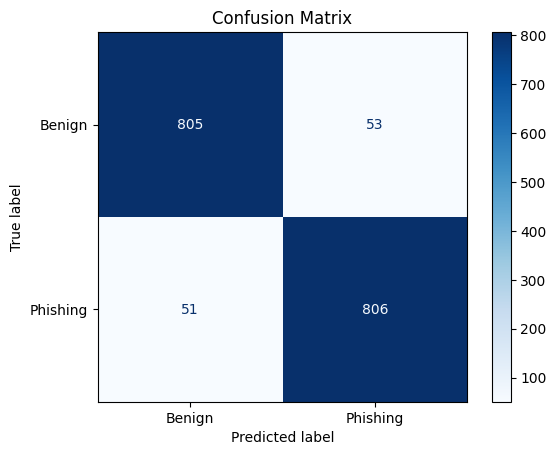

Classification Report:
               precision    recall  f1-score   support

      Benign       0.94      0.94      0.94       858
    Phishing       0.94      0.94      0.94       857

    accuracy                           0.94      1715
   macro avg       0.94      0.94      0.94      1715
weighted avg       0.94      0.94      0.94      1715



NameError: name 'best_by_model' is not defined

<Figure size 800x500 with 0 Axes>

In [50]:
# Show the best model results
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

# Confusion Matrix
cm = confusion_matrix(yte, yhat)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Benign", "Phishing"])
disp.plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

# Classification Report
print("Classification Report:\n", classification_report(yte, yhat, target_names=["Benign", "Phishing"]))

plt.figure(figsize=(8,5))
plt.bar(best_by_model["model"], best_by_model["test_acc"])
plt.title("Best Test Accuracy per Model")
plt.xlabel("Model")
plt.ylabel("Test Accuracy")
plt.xticks(rotation=20)
plt.ylim(0, 1)
plt.show()

# Save results to CSV
res_csv = "/content/results_summary.csv"
pd.DataFrame(results).to_csv(res_csv, index=False)
print("Saved:", res_csv)


**44_usingNN_Development of BiLSTM _(3 DatasetHere)_Bisltm_imagewith_diff_objectivefunction**

Install & Import Libraries

In [ ]:
!pip install gensim
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Embedding, Bidirectional, LSTM, GlobalMaxPooling1D, Dense, Dropout, Concatenate
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.initializers import Constant
import gensim
from gensim.models import Word2Vec



In [ ]:
X = df['url']
Y = df['label'].values
original_urls = df["url"].tolist()
original_url_lengths = [len(url) for url in original_urls]

URL Length Stats

In [ ]:
original_url_lengths = [len(url) for url in original_urls]
max_url = max(original_urls, key=len)
min_url = min(original_urls, key=len)
average_length = sum(original_url_lengths) / len(original_urls)


Clean URLs and Character Dictionary

In [ ]:
cleaned_urls = [re.sub(r'^https?:\/\/', '', url) for url in original_urls]
allowed_characters = sorted(set(''.join(cleaned_urls)))
char_dict = {char: idx + 1 for idx, char in enumerate(allowed_characters)}
char_dict['<PAD>'] = 0
char_dict['<UNK>'] = len(char_dict)
max_url_length = 300


Convert URLs to Char Vectors

In [ ]:
def url_to_char_vector(url):
    url = re.sub(r'^https?:\/\/', '', url)
    vector = [char_dict.get(char, char_dict['<UNK>']) for char in url[:max_url_length]]
    if len(vector) < max_url_length:
        vector += [char_dict['<PAD>']] * (max_url_length - len(vector))
    return vector

char_vectors = np.array([url_to_char_vector(url) for url in cleaned_urls])


Tokenization + Word2Vec

In [ ]:
def tokenize_url(url):
    url = re.sub(r'^https?:\/\/', '', url)
    return re.split(r'[\/\.\-\?\=\&\_]', url)

df['tokens'] = df['url'].apply(tokenize_url)
sentences = df['tokens'].tolist()
w2v_model = Word2Vec(sentences, vector_size=128, window=5, min_count=1, workers=4, sg=1)
word_index = {word: idx for idx, word in enumerate(w2v_model.wv.index_to_key)}
embedding_matrix = np.zeros((len(word_index), 128))
for word, i in word_index.items():
    embedding_matrix[i] = w2v_model.wv[word]


Token to Word Index Sequences

In [ ]:
def tokens_to_indices(tokens):
    return [word_index.get(token, 0) for token in tokens]

token_sequences = [tokens_to_indices(tokens) for tokens in df['tokens']]
max_token_number = max(len(tokens) for tokens in token_sequences)
token_sequences = pad_sequences(token_sequences, maxlen=max_token_number, padding='post')

X_train_char, X_test_char, X_train_word, X_test_word, y_train, y_test = train_test_split(
    char_vectors, token_sequences, Y, test_size=0.2, random_state=42)


Custom Attention Layer

In [ ]:
class Attention(tf.keras.layers.Layer):
    def __init__(self):
        super().__init__()

    def build(self, input_shape):
        self.W = self.add_weight(name='attention_weight', shape=(input_shape[-1], 1), initializer='random_normal', trainable=True)
        self.b = self.add_weight(name='attention_bias', shape=(input_shape[1], 1), initializer='zeros', trainable=True)

    def call(self, inputs):
        e = tf.keras.backend.tanh(tf.keras.backend.dot(inputs, self.W) + self.b)
        a = tf.keras.backend.softmax(e, axis=1)
        output = inputs * a
        return tf.keras.backend.sum(output, axis=1)


Define & Compile Model

In [ ]:
char_input = Input(shape=(max_url_length,), name='character_input')
char_embed = Embedding(len(char_dict), 128)(char_input)
char_lstm = Bidirectional(LSTM(128, return_sequences=True))(char_embed)
char_attention = Attention()(char_lstm)
char_drop = Dropout(0.5)(char_attention)

word_input = Input(shape=(max_token_number,), name='word_input')
word_embed = Embedding(input_dim=len(word_index), output_dim=128, embeddings_initializer=Constant(embedding_matrix), trainable=False)(word_input)
word_lstm = Bidirectional(LSTM(128, return_sequences=True))(word_embed)
word_attention = Attention()(word_lstm)
word_drop = Dropout(0.5)(word_attention)

concat = Concatenate()([char_drop, word_drop])
dense = Dense(64, activation='relu')(concat)
output = Dense(1, activation='sigmoid')(dense)

model = Model(inputs=[char_input, word_input], outputs=output)
model.compile(optimizer=Adam(), loss='binary_crossentropy', metrics=['accuracy'])


Train the Model

In [ ]:
model.fit([X_train_char, X_train_word], y_train, epochs=30, batch_size=128, validation_split=0.2)


Model Evakuation

In [ ]:
y_pred = model.predict([X_test_char, X_test_word])
y_pred_label = (y_pred > 0.5).astype(int)

print(classification_report(y_test, y_pred_label))
print(confusion_matrix(y_test, y_pred_label))
print('ROC AUC:', roc_auc_score(y_test, y_pred))


47_A hybrid DNN–LSTM model for detecting phishing URLs

In [12]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, classification_report, confusion_matrix
import re
from urllib.parse import urlparse
import string

# # 2. Read dataset
# file1_url = 'phishing.csv'
# file2_url = 'not-phishing.csv'

# df1 = pd.read_csv(file1_url)
# df2 = pd.read_csv(file2_url)

# df2['brands'] = pd.NA

# # Combine datasets
# combined_df = pd.concat([df1, df2], ignore_index=True)
# combined_df['label'] = combined_df['security_state'].map({'insecure': 0, 'secure': 1})
# combined_df = combined_df[['url', 'label']].dropna(subset=["url", "label"]).copy()

# # Check the first few rows of the combined dataset
# print(combined_df.head())

# # 3. Label encoding
# df = combined_df.copy()  # Updated dataset
# df['label'] = df['label'].astype(np.float32)

# 4. Character vocabulary for URL embedding
ALL_CHARS = string.ascii_letters + string.digits + string.punctuation
char2idx = {ch: idx + 1 for idx, ch in enumerate(ALL_CHARS)}  # 0 reserved for padding

def char_encode(url, max_len=150):
    encoded = [char2idx.get(ch, 0) for ch in url[:max_len]]
    if len(encoded) < max_len:
        encoded += [0] * (max_len - len(encoded))
    return encoded

# 5. Feature Engineering: 40 handcrafted NLP features
def extract_features(url):
    parsed = urlparse(url)
    hostname = parsed.hostname if parsed.hostname else ''
    path = parsed.path if parsed.path else ''
    features = []

    features.append(len(url))
    features.append(url.count('.'))
    features.append(url.count('-'))
    features.append(url.count('@'))
    features.append(url.count('?'))
    features.append(url.count('&'))
    features.append(url.count('='))
    features.append(url.count('_'))
    features.append(url.count('~'))
    features.append(url.count('/'))
    features.append(len(path))
    features.append(path.count('/'))
    features.append(path.count('-'))
    features.append(path.count('.'))
    features.append(len(hostname))
    features.append(hostname.count('.'))
    features.append(hostname.count('-'))
    features.append(hostname.startswith('www'))
    features.append(bool(re.match(r'^\d+\.\d+\.\d+\.\d+$', hostname)))
    features.append(int(url.lower().startswith('https')))
    features.append('login' in url.lower())
    features.append('secure' in url.lower())
    features.append('account' in url.lower())
    features.append('update' in url.lower())
    features.append('free' in url.lower())
    features.append('verify' in url.lower())
    features.append(sum(c.isdigit() for c in url))
    features.append('//' in url[7:])
    features.append('.com' in url)
    features.append('.net' in url)
    features.append('.org' in url)
    features.append('.gov' in url)
    features.append(any(short in url for short in ['bit.ly', 'tinyurl', 'goo.gl', 'ow.ly', 't.co', 'bit.do']))
    features.append(len(set(url)) / (len(url) + 1e-5))
    return features

# 6. Apply feature extraction
X_nlp = np.array([extract_features(url) for url in df['url']])
X_char = np.array([char_encode(url) for url in df['url']])
y = df['label'].values

# Outlier Removal using Boxplot (IQR Method)

# Convert to DataFrame for easier processing
X_nlp_df = pd.DataFrame(X_nlp)

# Identify outliers for each feature
outlier_indices = set()

for col in X_nlp_df.columns:
    Q1 = X_nlp_df[col].quantile(0.25)
    Q3 = X_nlp_df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    # Find indices where outliers exist
    outliers = X_nlp_df[(X_nlp_df[col] < lower_bound) | (X_nlp_df[col] > upper_bound)].index
    outlier_indices.update(outliers)

# Remove outlier rows
print(f"Removing {len(outlier_indices)} outliers from data...")

X_nlp_cleaned = X_nlp_df.drop(index=outlier_indices).values
X_char_cleaned = np.delete(X_char, list(outlier_indices), axis=0)
y_cleaned = np.delete(y, list(outlier_indices), axis=0)

# 7. Train-test split
X_nlp_train, X_nlp_test, X_char_train, X_char_test, y_train, y_test = train_test_split(
    X_nlp_cleaned, X_char_cleaned, y_cleaned, test_size=0.2, random_state=42)

# 8. Scale NLP features
scaler = StandardScaler()
X_nlp_train_scaled = scaler.fit_transform(X_nlp_train)
X_nlp_test_scaled = scaler.transform(X_nlp_test)

# 9. Custom Dataset
class HybridPhishingDataset(Dataset):
    def __init__(self, nlp_feats, char_seqs, labels):
        self.nlp = torch.tensor(nlp_feats, dtype=torch.float32)
        self.char = torch.tensor(char_seqs, dtype=torch.long)
        self.labels = torch.tensor(labels, dtype=torch.float32)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return self.nlp[idx], self.char[idx], self.labels[idx]

train_data = HybridPhishingDataset(X_nlp_train_scaled, X_char_train, y_train)
test_data = HybridPhishingDataset(X_nlp_test_scaled, X_char_test, y_test)

train_loader = DataLoader(train_data, batch_size=128, shuffle=True)
test_loader = DataLoader(test_data, batch_size=128)

# 10. Corrected Hybrid DNN + BiLSTM Model
class HybridDNNBiLSTM(nn.Module):
    def __init__(self, nlp_input_dim, vocab_size=len(char2idx) + 1, embed_dim=128):
        super(HybridDNNBiLSTM, self).__init__()

        # LSTM branch
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.bilstm = nn.LSTM(embed_dim, 32, num_layers=1, batch_first=True, bidirectional=True)
        self.lstm_fc1 = nn.Linear(64, 32)  # 32*2 because of bidirectional
        self.lstm_fc2 = nn.Linear(32, 16)
        self.lstm_fc3 = nn.Linear(16, 8)

        # DNN branch
        self.fc1 = nn.Linear(nlp_input_dim, 64)
        self.fc2 = nn.Linear(64, 32)
        self.fc3 = nn.Linear(32, 16)

        # Combined layer
        self.combined_fc1 = nn.Linear(16 + 8, 8)
        self.output_fc = nn.Linear(8, 1)

        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.3)
        self.sigmoid = nn.Sigmoid()

    def forward(self, nlp_input, char_input):
        # LSTM path
        x2 = self.embedding(char_input)
        lstm_out, _ = self.bilstm(x2)
        x2 = lstm_out[:, -1, :]  # Take the last time step output
        x2 = self.relu(self.lstm_fc1(x2))
        x2 = self.dropout(self.relu(self.lstm_fc2(x2)))
        x2 = self.dropout(self.relu(self.lstm_fc3(x2)))

        # DNN path
        x1 = self.relu(self.fc1(nlp_input))
        x1 = self.relu(self.fc2(x1))
        x1 = self.dropout(self.relu(self.fc3(x1)))

        # Merge
        x = torch.cat((x1, x2), dim=1)
        x = self.relu(self.combined_fc1(x))
        x = self.sigmoid(self.output_fc(x))
        return x.squeeze()

# 11. Training Setup
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = HybridDNNBiLSTM(nlp_input_dim=X_nlp_train_scaled.shape[1]).to(device)
criterion = nn.BCELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

num_epochs = 40
for epoch in range(num_epochs):
    model.train()
    total_loss = 0
    for nlp_batch, char_batch, y_batch in train_loader:
        nlp_batch, char_batch, y_batch = nlp_batch.to(device), char_batch.to(device), y_batch.to(device)
        optimizer.zero_grad()
        outputs = model(nlp_batch, char_batch)
        loss = criterion(outputs, y_batch)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {total_loss:.4f}")

# 12. Evaluation
model.eval()
all_preds = []
all_labels = []
all_probs = []

with torch.no_grad():
    for nlp_batch, char_batch, y_batch in test_loader:
        nlp_batch, char_batch, y_batch = nlp_batch.to(device), char_batch.to(device), y_batch.to(device)
        outputs = model(nlp_batch, char_batch)
        preds = (outputs >= 0.5).long()
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(y_batch.cpu().numpy())
        all_probs.extend(outputs.cpu().numpy())

print("\nClassification Report:\n", classification_report(all_labels, all_preds))
print("Confusion Matrix:\n", confusion_matrix(all_labels, all_preds))
print(f"Accuracy: {accuracy_score(all_labels, all_preds):.4f}")
print(f"F1 Score: {f1_score(all_labels, all_preds):.4f}")
print(f"AUC Score: {roc_auc_score(all_labels, all_probs):.4f}")


Removing 8216 outliers from data...
Epoch [1/40], Loss: 13.8974
Epoch [2/40], Loss: 13.5813
Epoch [3/40], Loss: 13.0034
Epoch [4/40], Loss: 11.1229
Epoch [5/40], Loss: 9.0627
Epoch [6/40], Loss: 7.8883
Epoch [7/40], Loss: 7.9800
Epoch [8/40], Loss: 8.0744
Epoch [9/40], Loss: 7.5715
Epoch [10/40], Loss: 7.5883
Epoch [11/40], Loss: 7.3130
Epoch [12/40], Loss: 7.2136
Epoch [13/40], Loss: 7.2675
Epoch [14/40], Loss: 7.0099
Epoch [15/40], Loss: 7.0259
Epoch [16/40], Loss: 7.0414
Epoch [17/40], Loss: 6.8415
Epoch [18/40], Loss: 7.1776
Epoch [19/40], Loss: 7.0644
Epoch [20/40], Loss: 6.9741
Epoch [21/40], Loss: 6.8645
Epoch [22/40], Loss: 6.7816
Epoch [23/40], Loss: 6.7244
Epoch [24/40], Loss: 7.0616
Epoch [25/40], Loss: 6.6478
Epoch [26/40], Loss: 6.6829
Epoch [27/40], Loss: 6.6341
Epoch [28/40], Loss: 6.4536
Epoch [29/40], Loss: 6.9250
Epoch [30/40], Loss: 6.8602
Epoch [31/40], Loss: 6.6820
Epoch [32/40], Loss: 6.5012
Epoch [33/40], Loss: 6.6116
Epoch [34/40], Loss: 6.3350
Epoch [35/40], Lo

46_Phishing_URL_Detection_via_CNN_and_Attention-Based_Hierarchical_RNN

In [ ]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, accuracy_score, precision_score, confusion_matrix
import re

DEVICE = torch.device("cpu")

######################################
# STEP 1 - Load and clean dataset
######################################
import pandas as pd

#url = 'Shashwatwork.csv'
df = pd.read_csv('../dataset_phishing.csv')


expected_cols = {"url", "status"}

if 'url' not in df.columns or 'status' not in df.columns:
    print("Available columns:", df.columns.tolist())
    if 'url' not in df.columns:
        print("'url' column not found in the dataset.")
    if 'status' not in df.columns:
        print("'status' column not found in the dataset.")


df['label'] = df['status'].map({'legitimate': 0, 'phishing': 1})
df = df[['url', 'label']].dropna(subset=["url", "label"]).copy()
df["label"] = df["label"].astype(int)

print(df.head())

print("Class balance:\n", df["label"].value_counts())


######################################
# STEP 2 - Feature Engineering (URL-based)
######################################

# Extract features from URLs
df_features = pd.DataFrame()
df_features['url_length'] = df['url'].apply(len)
df_features['num_dots'] = df['url'].apply(lambda x: x.count('.'))
df_features['num_hyphens'] = df['url'].apply(lambda x: x.count('-'))
df_features['num_slashes'] = df['url'].apply(lambda x: x.count('/'))
df_features['num_digits'] = df['url'].apply(lambda x: sum(c.isdigit() for c in x))
df_features['has_https'] = df['url'].apply(lambda x: int('https' in x.lower()))
df_features['has_login'] = df['url'].apply(lambda x: int('login' in x.lower()))
df_features['has_secure'] = df['url'].apply(lambda x: int('secure' in x.lower()))


df=df.reset_index(drop=True)
df_features=df_features.reset_index(drop=True)
df_features=df_features.dropna().add_suffix('_feature')

# # Combine with original data for easier filtering
# df_combined = pd.concat([df, df_features], axis=1)

# # Function to remove outliers using IQR method
# def remove_outliers_iqr(data, columns):
#     for column in columns:
#         Q1 = data[column].quantile(0.25)
#         Q3 = data[column].quantile(0.75)
#         IQR = Q3 - Q1
#         lower_bound = Q1 - 1.5 * IQR
#         upper_bound = Q3 + 1.5 * IQR
#         data = data[(data[column] >= lower_bound) & (data[column] <= upper_bound)]
#     return data

# # Columns to check for outliers
# feature_columns = df_features.columns.tolist()
# df_combined=df_combined.drop_duplicates()
# # Remove outliers
# df = remove_outliers_iqr(df_combined, feature_columns)

######################################
# STEP 3 - Preprocessing (Viterbi Segmentation + Tokenization)
######################################

# Basic vocabulary for segmenting URL into meaningful words
ENGLISH_WORDS = set(['login','secure','account','update','free','email','paypal','bank','confirm','password','signin','signin','admin','support','service','online','web','client','server'])

# This is a basic Viterbi algorithm for breaking a string into known words using dynamic programming
def viterbi_segment(text, vocab=ENGLISH_WORDS):
    n = len(text)
    probs = [0] * (n+1)
    lasts = [0] * (n+1)
    probs[0] = 1

    for i in range(1, n+1):
        prob_k = []
        for k in range(max(0,i-20), i):
            word = text[k:i]
            if word.lower() in vocab:
                prob_k.append((probs[k]*1.0, k))
            else:
                prob_k.append((probs[k]*0.01, k))
        probs[i], lasts[i] = max(prob_k)

    words = []
    i = n
    while i > 0:
        k = lasts[i]
        words.append(text[k:i])
        i = k
    return list(reversed(words))

def preprocess_url(url, max_chars=200, max_words=200, max_word_len=32):
    # Remove non-alphanumeric characters for words
    tokens = re.findall(r"[a-zA-Z0-9]+", url)
    segmented = []
    for token in tokens:
        segmented.extend(viterbi_segment(token))

    # Character-level processing
    url_chars = list(url.lower())
    if len(url_chars) > max_chars:
        url_chars = url_chars[:max_chars]
    else:
        url_chars += ['<PAD>'] * (max_chars - len(url_chars))

    # Word-level processing
    if len(segmented) > max_words:
        segmented = segmented[:max_words]
    else:
        segmented += ['<PAD>'] * (max_words - len(segmented))

    word_characters = []
    for word in segmented:
        w = list(word.lower())
        if len(w) > max_word_len:
            w = w[:max_word_len]
        else:
            w += ['<PAD>'] * (max_word_len - len(w))
        word_characters.append(w)

    return url_chars, word_characters

# Build character vocabulary
ALL_CHARS = list("abcdefghijklmnopqrstuvwxyz0123456789:/?&.=#%-_+~") + ['<PAD>']
char2idx = {c:i for i,c in enumerate(ALL_CHARS)}

######################################
# STEP 4 - Dataset & DataLoader
######################################

class PhishingDataset(Dataset):
    def __init__(self, df):
        self.urls = df['url'].values
        self.labels = df['label'].values

    def __len__(self):
        return len(self.urls)

    def __getitem__(self, idx):
        url = self.urls[idx]
        label = self.labels[idx]
        char_seq, word_seq = preprocess_url(url)

        # Encoding the characters and words
        char_encoded = [char2idx.get(c, char2idx['<PAD>']) for c in char_seq]
        word_encoded = [[char2idx.get(c, char2idx['<PAD>']) for c in word] for word in word_seq]

        return torch.tensor(char_encoded), torch.tensor(word_encoded), torch.tensor(label)

# Split dataset into train/test sets
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)
train_dataset = PhishingDataset(train_df)
test_dataset = PhishingDataset(test_df)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64)

######################################
# STEP 5 - Build PhishingNet Model
######################################

class Attention(nn.Module):
    def __init__(self, hidden_size):
        super().__init__()
        self.attention = nn.Linear(hidden_size, 1)

    def forward(self, encoder_outputs):
        weights = torch.softmax(self.attention(encoder_outputs), dim=1)
        outputs = (encoder_outputs * weights).sum(dim=1)
        return outputs

class PhishingNet(nn.Module):
    def __init__(self, vocab_size=len(ALL_CHARS), emb_dim=128):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim)

        # Character-level CNN Module
        self.char_conv = nn.Sequential(
              nn.Conv1d(emb_dim, 256, kernel_size=5),
              nn.ReLU(),
              nn.MaxPool1d(2),
              nn.Conv1d(256, 128, kernel_size=5),
              nn.ReLU(),
              nn.MaxPool1d(2),
              nn.Conv1d(128, 64, kernel_size=3),
              nn.ReLU(),
              nn.MaxPool1d(2)
        )

        # Word-level Hierarchical RNN with Attention
        self.char_lstm = nn.LSTM(emb_dim, 64, batch_first=True, bidirectional=True)
        self.word_lstm = nn.LSTM(128, 64, batch_first=True, bidirectional=True)
        self.attention = Attention(128)

        # Dummy forward to calculate char feature size dynamically
        dummy_input = torch.zeros(1, 200, dtype=torch.long)
        dummy_emb = self.embedding(dummy_input).transpose(1,2)
        dummy_feat = self.char_conv(dummy_emb)
        char_feat_dim = dummy_feat.view(1, -1).size(1)

        self.fc = nn.Sequential(
            nn.Linear(char_feat_dim + 128, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, 1)
        )

    def forward(self, char_input, word_input):
        emb_char = self.embedding(char_input).transpose(1,2)
        char_features = self.char_conv(emb_char)
        char_features = char_features.view(char_features.size(0), -1)

        B, W, C = word_input.shape
        word_input = word_input.view(B*W, C)
        emb_word_chars = self.embedding(word_input)
        word_char_features, _ = self.char_lstm(emb_word_chars)
        word_char_features = word_char_features[:, -1, :]
        word_char_features = word_char_features.view(B, W, -1)

        word_seq_features, _ = self.word_lstm(word_char_features)
        word_features = self.attention(word_seq_features)

        features = torch.cat([char_features, word_features], dim=1)
        output = self.fc(features)
        return output.squeeze()

# Initialize the model
model = PhishingNet().to(DEVICE)

######################################
# STEP 6 - Loss Function + Optimizer
######################################

criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=0.0001)

######################################
# STEP 7 - Training and Evaluation
######################################

def train(model, loader):
    model.train()
    total_loss = 0
    for chars, words, labels in loader:
        chars, words, labels = chars.to(DEVICE), words.to(DEVICE), labels.float().to(DEVICE)
        optimizer.zero_grad()
        outputs = model(chars, words)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    return total_loss / len(loader)

def evaluate(model, loader):
    model.eval()
    y_true, y_pred, y_score = [], [], []
    with torch.no_grad():
        for chars, words, labels in loader:
            chars, words, labels = chars.to(DEVICE), words.to(DEVICE), labels.float().to(DEVICE)
            outputs = model(chars, words)
            probs = torch.sigmoid(outputs)
            preds = (probs > 0.5).long()

            y_true.extend(labels.cpu().numpy())
            y_pred.extend(preds.cpu().numpy())
            y_score.extend(probs.cpu().numpy())

    auc = roc_auc_score(y_true, y_score)
    acc = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred)
    cm = confusion_matrix(y_true, y_pred)
    fpr = cm[0][1] / (cm[0][0] + cm[0][1])
    return auc, acc, precision, fpr

# Train and evaluate for 5 epochs
for epoch in range(5):
    train_loss = train(model, train_loader)
    auc, acc, precision, fpr = evaluate(model, test_loader)
    print(f"Epoch {epoch+1}: Loss={train_loss:.4f} | AUC={auc:.4f} | ACC={acc:.4f} | Precision={precision:.4f} | FPR={fpr:.4f}")


                                                 url  label
0              http://www.crestonwood.com/router.php      0
1  http://shadetreetechnology.com/V4/validation/a...      1
2  https://support-appleld.com.secureupdate.duila...      1
3                                 http://rgipt.ac.in      0
4  http://www.iracing.com/tracks/gateway-motorspo...      0
Class balance:
 0    5715
1    5715
Name: label, dtype: int64
Epoch 1: Loss=0.5314 | AUC=0.9227 | ACC=0.8259 | Precision=0.7771 | FPR=0.2541
Epoch 2: Loss=0.3335 | AUC=0.9543 | ACC=0.8775 | Precision=0.8471 | FPR=0.1616
Epoch 3: Loss=0.2654 | AUC=0.9650 | ACC=0.8955 | Precision=0.8778 | FPR=0.1245
Epoch 4: Loss=0.2200 | AUC=0.9710 | ACC=0.9064 | Precision=0.9193 | FPR=0.0761
Epoch 5: Loss=0.1862 | AUC=0.9693 | ACC=0.9081 | Precision=0.9196 | FPR=0.0761


In [7]:
from sklearn.metrics import classification_report, confusion_matrix
import torch
import torch.nn as nn

# Ensure model is in evaluation mode
model.eval()

# Collect all outputs and labels
y_true, y_pred, y_score = [], [], []
test_loss = 0.0
criterion = nn.BCEWithLogitsLoss()

with torch.no_grad():
    for chars, words, labels in test_loader:
        chars, words, labels = chars.to(DEVICE), words.to(DEVICE), labels.float().to(DEVICE)
        outputs = model(chars, words)
        loss = criterion(outputs, labels)
        test_loss += loss.item() * labels.size(0)

        probs = torch.sigmoid(outputs)
        preds = (probs > 0.5).long()

        y_true.extend(labels.cpu().numpy())
        y_pred.extend(preds.cpu().numpy())
        y_score.extend(probs.cpu().numpy())

# Average test loss
test_loss /= len(test_loader.dataset)

# Metrics
test_accuracy = accuracy_score(y_true, y_pred)
test_auc = roc_auc_score(y_true, y_score)

print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_accuracy:.4f}")
print(f"ROC AUC Score : {test_auc:.4f}")

print("\n===== CLASSIFICATION REPORT =====")
print(classification_report(y_true, y_pred, digits=4))

cm = confusion_matrix(y_true, y_pred)
print("\nConfusion Matrix:")
print(cm)


Test Loss     : 0.2239
Test Accuracy : 0.9081
ROC AUC Score : 0.9693

===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

         0.0     0.8976    0.9239    0.9106      1157
         1.0     0.9196    0.8919    0.9056      1129

    accuracy                         0.9081      2286
   macro avg     0.9086    0.9079    0.9081      2286
weighted avg     0.9085    0.9081    0.9081      2286


Confusion Matrix:
[[1069   88]
 [ 122 1007]]


In [64]:
import torch
print(torch.__version__)
print(torch.version.cuda)

1.13.1+cu117
11.7
